In [2]:
import numpy as np
import matplotlib.pyplot as plt

import os
from statsmodels.stats.weightstats import DescrStatsW

import numpy as np
import scipy.stats as stats

In [ ]:
#Question:
#Does solvation (hydrogen bonding with water) shift the rotamer distribution of threonines on helices?

def heatmap_1(rotamer_data, hbond_data, helix_data, framerates):

    #change in delta-g of adopting the 180 degree rotamer between wet and dry conditions
    ddG_all = []
    #length of simulation for which residue is on a helix
    weights_all = [] 

    for nr in range(rotamer_data.shape[0]):

        helix_rotamer_hbonds = np.zeros((2,3,3))

        for x,y,z,f in zip(helix_data[nr], rotamer_data[nr], hbond_data[nr], framerates):
            helix_rotamer_hbonds[x,y,z]+=1/f

        r_hb = np.array([[helix_rotamer_hbonds[1,0,0],           np.sum(helix_rotamer_hbonds[1,0,1:3])],
                         [np.sum(helix_rotamer_hbonds[1,1:3,0]), np.sum(helix_rotamer_hbonds[1,1:3,1:3])]])

        plot_mat = False
        if plot_mat:
            print(helix_rotamer_hbonds[1])
            plt.imshow(helix_rotamer_hbonds[1])
            plt.ylabel("rotamer")
            plt.xlabel("number of hydrogen bonds")
            plt.yticks([0,1,2],[180, -60, 60])
            plt.xticks([0,1,2],[0,1,2])
            plt.show()
        #print(np.sum(helix_rotamer_hbonds)/5000)

        #calculate effect of hydrogen bonding with water on rotamer free energy
        #we can't do this calculation unless we have sampled in all four states
        if np.all(r_hb>0): 

            dG_rot_dry = -np.log(r_hb[0,0]/r_hb[1,0])
            dG_rot_wet = -np.log(r_hb[0,1]/r_hb[1,1])

            ddG_all.append(dG_rot_wet-dG_rot_dry)
            weights_all.append(np.sum(r_hb))
            #print(np.sum(r_hb)/5000)

            plot_mat_2 = False
            if plot_mat_2:
                print(helix_rotamer_hbonds[1])
                plt.imshow(helix_rotamer_hbonds[1])
                plt.ylabel("rotamer")
                plt.xlabel("number of hydrogen bonds")
                plt.yticks([0,1,2],[180, -60, 60])
                plt.xticks([0,1,2],[0,1,2])
                plt.show()
    # plt.hist(dg_all, weights = weights_all, bins=20, range = (-5,5), density = True)
    # plt.show()
    print(f"raw delta-delta-G values: {ddG_all}")

    confidence_level = 0.95
    # we don't know if the set of delta G values from all relevant protein chemical environments is t-distributed
    # and there is not really any good reason to expect it to be in general
    ci = stats.t.interval(confidence_level, df=len(ddG_all)-1, loc=np.mean(ddG_all), scale=np.std(ddG_all, ddof=1) / np.sqrt(len(ddG_all)))
    print(f"single-protein {confidence_level*100}% t test confidence interval: {ci}")

    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"single-protein {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")

    #MG meeting list
    #TODO-N/A; also get a spearman CI - this does not appear to be the right test for this purpose
    #TODO-done: try bootstrapping - this yields smaller 95% CIs than the t test
    # for our small sample sizes this may actually be worse:  Am Stat. 2015 Dec 29;69(4):371–386. doi: 10.1080/00031305.2015.1089789 
    # consider the example of 10 data points at x=-0.1 and 10 data points at x=-1.1. 
    #   Drawing bootstrap samples and computing the mean will always yield values in the range [-1.1,-0.1], so the 95% CI will not contain 0.
    #   However computing the standard deviation 
    #TODO try giving each site a fixed solvation assignment and then testing the 
    # difference of means between the deltaG +-60/180 for solvated and non-solvated ones 
    #TODO write code to print the delta G of different residues by protein and pdb index
    #TODO multiply delta G value based on hbond frac in "solvated" helices and non-solvated ones 
    # to get actual rotamer delta-G for membrane and water helices given the imperfect correspondence between solvent and hydrogen bond formation
    #TODO-done - look at transitions: everything has at least a few rotamer transitions each way even in one short segment so nothing is so kinetically trapped
    # that it needs to be thrown out
    
    return ddG_all, weights_all


In [56]:
def hist_fixed_class(rotamer_data, hbond_data, helix_data):

    dG_dry = []
    dG_wet = []
    dG_interfacial = []

    dG_all = []
    hbond_t_frac_all = []

    helicity_thresh = 0.75

    rotamer_data_180deg = np.where(rotamer_data==0, 1, 0)

    for nr in range(rotamer_data.shape[0]):
        if np.sum(helix_data[nr])/len(helix_data[nr]) >= helicity_thresh:
            if np.sum(rotamer_data_180deg[nr]) > 0 and (len(rotamer_data_180deg[nr])-np.sum(rotamer_data_180deg[nr])) > 0:
                
                dG = -np.log(np.sum(rotamer_data_180deg[nr])/(len(rotamer_data_180deg[nr])-np.sum(rotamer_data_180deg[nr])))
                dG_all.append(dG)
                hbond_t_frac = np.sum(hbond_data[nr])/len(hbond_data[nr])
                hbond_t_frac_all.append(hbond_t_frac)
                print(hbond_t_frac)

                # if hbond_t_frac > 0.5:
                #     dG_wet.append(dG)
                # elif hbond_t_frac < 0.5:
                #     dG_dry.append(dG)
                # else:
                #     dG_interfacial.append(dG)

    return dG_all, hbond_t_frac_all #dG_dry, dG_wet, dG_interfacial

In [57]:
def load_process(analysis_method, resn):

    #this path actually also contains serine rotamers
    inputpath = "/home/jonathan/Documents/grabelab/rutter-lab-collaboration/thr_rotamers_solvation/resi_data"

    servers = ["wynton", "degrabo"]
    proteins = ["ucp1", "aac1"]

    # dG_dry_all = []
    # dG_wet_all = []
    # dG_interfacial_all = []
    dG_all = []
    hbond_t_frac_all = []

    #loop over servers, proteins, and parallel runs
    for protein in proteins:

        print("---------------------------------------------: " +protein)
        rotamer_data = []
        hbond_data = []
        helix_data = []
        framerates = []

        for server in servers:    
            for run in range(1,5):
                #not all servers have the same number of parallel simulations
                if run > 2 and server == "degrabo": continue

                if run > 2:
                    framerate = 2
                else:
                    framerate = 1

                for seg in range(1,20):
                    #load data if it exists
                    rotamer_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-rotamers.npy"
                    hbond_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-hbonds.npy"
                    secstr_file = f"{inputpath}/{server}/{protein}/run0{run}/{protein}-{server}-run0{run}-seg{str(seg).zfill(2)}-{resn}-secstr.npy"

                    if os.path.exists(rotamer_file) and os.path.exists(hbond_file) and os.path.exists(secstr_file):
                        rotamer_data.append(np.load(rotamer_file))
                        hbond_data.append(np.load(hbond_file))
                        helix_data.append(np.load(secstr_file))
                        framerates.append(framerate*np.ones(rotamer_data[-1].shape[1]))


        rotamer_data = np.concatenate(rotamer_data, axis = 1)
        hbond_data = np.concatenate(hbond_data, axis = 1)
        helix_data = np.concatenate(helix_data, axis = 1)
        framerates = np.concatenate(framerates, axis = 0)

        dG, hbond_t_frac = analysis_method(rotamer_data, hbond_data, helix_data)

        print(dG)
        print(hbond_t_frac)

        dG_all.append(dG)
        hbond_t_frac_all.append(hbond_t_frac)

        # dG_dry, dG_wet, dG_interfacial = analysis_method(rotamer_data, hbond_data, helix_data)
        # dG_dry_all.append(dG_dry)
        # dG_wet_all.append(dG_wet)
        # dG_interfacial_all.append(dG_interfacial)

    # print(list(dG_wet_all))
    # print(list(dG_dry_all))
    # print(list(dG_interfacial_all))

    # dG_dry_all = np.concatenate(dG_dry_all)
    # dG_wet_all = np.concatenate(dG_wet_all)
    # dG_interfacial_all = np.concatenate(dG_interfacial_all)
    print(dG_all)
    print(hbond_t_frac_all)

    dG_all = np.concatenate(dG_all)
    hbond_t_frac_all = np.concatenate(hbond_t_frac_all)

    return dG_all, hbond_t_frac_all #dG_dry_all, dG_wet_all, dG_interfacial_all


---------------------------------------------: ucp1
0.08680722967335662
0.4149473622425236
0.7778229644008603
0.759010888112797
0.007752067986768239
0.21486518780631989
0.6775953076719898
0.8603453841864521
0.7459803703719232
0.004502823698101183
0.007051908249726435
0.5621150693661249
0.5805833546455809
0.8450131437172194
[7.766651809173982, 3.6146490912575726, 7.123895195333997, 2.024421769717834, 7.370931487676962, 5.927485280704487, 5.363607347624965, 1.051104909077025, 5.638123283774958, 8.430734109436084, 8.980872698825273, 6.60009303260951, 8.85569278332792, 2.4994897036341595]
[0.08680722967335662, 0.4149473622425236, 0.7778229644008603, 0.759010888112797, 0.007752067986768239, 0.21486518780631989, 0.6775953076719898, 0.8603453841864521, 0.7459803703719232, 0.004502823698101183, 0.007051908249726435, 0.5621150693661249, 0.5805833546455809, 0.8450131437172194]
---------------------------------------------: aac1
0.008630434608323379
0.6811349041552757
0.007956996143763079
0.15321

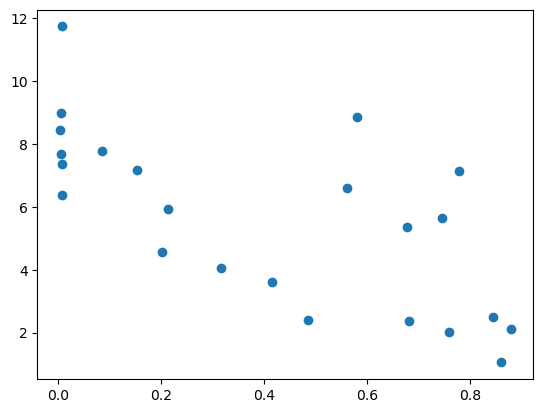

In [58]:
resn = "thr"
dG_all, hbond_t_frac_all = load_process(hist_fixed_class, resn)

plt.scatter(hbond_t_frac_all, dG_all)
print(f"using {len(dG_all)} total residues")

In [ ]:
#the other notebook measures P(180|hbond)/P(180|no hbond) = A
#this one measures P(180|solvent exposed)/P(180|membrane exposed) = B

#P(180|solvent exposed) = P(180|hbond)*P(hbond | solvent exposed) + P(180|no hbond)*P(no hbond | solvent exposed) =~ P(180|hbond)
#P(180|membrane exposed) = P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond)*P(no hbond | membrane exposed) 
# =~ P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond)
#note that both terms of this latter equation are small

#B = P(180|solvent exposed)/P(180|membrane exposed) =~ P(180|hbond)/(P(180|hbond)*P(hbond | membrane exposed) + P(180|no hbond))
#1/B =~ 1/A + P(hbond | membrane exposed) # A is generally large so both of these terms are small
#so B deviates from A by an amount proportional to the energetic cost of bringing water into the membrane



#VV WRONG VERSION VV
#B = A*P(hbond|solvent exposed)/P(no hbond|membrane exposed)
#in theory A should be close to B because both the numerator and denominator of the conversion factor are close to 1


---------------------------------------------: ucp1
0.08680722967335662
0.4149473622425236
0.7778229644008603
0.759010888112797
0.007752067986768239
0.21486518780631989
0.6775953076719898
0.8603453841864521
0.7459803703719232
0.004502823698101183
0.007051908249726435
0.5621150693661249
0.5805833546455809
0.8450131437172194
---------------------------------------------: aac1
0.008630434608323379
0.6811349041552757
0.007956996143763079
0.15321526781204653
0.4865232135842159
0.317458090481268
0.006614127776931526
0.8794545148437062
0.20293346588312636
using 23 total residues


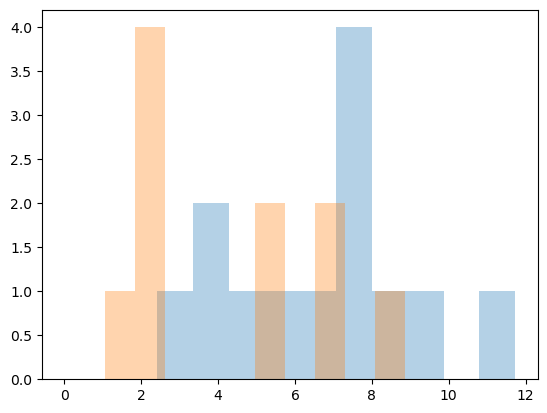

In [39]:
resn = "thr"
dG_dry_all, dG_wet_all, dG_interfacial_all = load_process(hist_fixed_class, resn)
plt.hist(dG_dry_all, alpha=1/3)
plt.hist(dG_wet_all, alpha=1/3)
plt.hist(dG_interfacial_all, alpha=1/3)

print(f"using {len(dG_dry_all)+len(dG_wet_all)+len(dG_interfacial_all)} total residues")



In [11]:
    
def compile_results(ddG_all, weights_all, resn):

    plot_with_alldata = False
    if plot_with_alldata:
        plt.show()
        plt.scatter(weights_all, ddG_all)

        plt.show()
        plt.hist(ddG_all, weights = weights_all, bins=20, range = (-5,5), density = True)

        confidence_level = 0.99
        # ci = stats.t.interval(confidence_level, df=len(dg_all)-1, loc=np.mean(dg_all), scale=np.std(dg_all, ddof=1) / np.sqrt(len(dg_all)))
        # print(f"{confidence_level*100}% confidence interval: {ci}")
        bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
        print(f"single-protein {confidence_level*100}% confidence interval: {bootstrap_result.confidence_interval}")

    ddG_mostlyhelical = []
    weights_mostlyhelical = []

    #print(weights_all)

    for d, w in zip(ddG_all, weights_all):
        if w >= max(weights_all)*1/2:
            ddG_mostlyhelical.append(d)
            weights_mostlyhelical.append(w)

    print("---------------------------------------------: overall")
    
    print(f"data for {len(ddG_mostlyhelical)} residues")
    print(f"each residue used below has at least {min(weights_mostlyhelical)/5000} microseconds of aggregate data in a helix")
    print(f"water H-bonding favors 180 degree rotamer by {-np.mean(ddG_mostlyhelical):.2f} kT on helices")

    printrange=False
    if printrange:
        print(min(ddG_mostlyhelical))
        print(max(ddG_mostlyhelical))

    plt.show()
    plt.hist(ddG_mostlyhelical, bins=14, range = (-3.5,3.5), density = True)
    plt.xlim(-3.5,3.5)
    plt.ylim(0,0.5)
    plt.xlabel("free energy change of 180 degree\nrotamer upon water H-bonding (kT)")
    plt.ylabel("probability density")
    plt.savefig(f"figures/{resn}-rotamer-free-energy.png", bbox_inches="tight", dpi=600)

    confidence_level = 0.95
    ci = stats.t.interval(confidence_level, df=len(ddG_mostlyhelical)-1, loc=np.mean(ddG_mostlyhelical), scale=np.std(ddG_mostlyhelical, ddof=1) / np.sqrt(len(ddG_mostlyhelical)))
    print(f"2-protein combined {confidence_level*100}% t-test confidence interval: {ci}")
    bootstrap_result = stats.bootstrap(data=(ddG_all,), statistic=np.mean, n_resamples=9999, confidence_level=confidence_level)
    print(f"2-protein combined {confidence_level*100}% bootstrap confidence interval: ({bootstrap_result.confidence_interval.low}, {bootstrap_result.confidence_interval.high})")


---------------------------------------------: ucp1
raw delta-delta-G values: [-3.1641713445490147, -1.8681396132618273, -1.4140123881446232, -0.28137064799991407, -0.7002156310382674, 0.18131874001650727, -0.10536051565782635, -0.6029214791376152, -1.8759343560760708, 1.792574396131437, -0.4315230781134711, -1.2882316077557086, -0.4285865170823935, -4.424463324871138, -2.342533874736934, -1.3752015207543398, -0.2970222689873614, 0.6635120334435616, -0.77872922701212, 0.7851217262410932]
single-protein 95.0% t test confidence interval: (-1.558143983889316, -0.2374450660452866)
single-protein 95.0% bootstrap confidence interval: (-1.5857710829091423, -0.36062042438309594)
---------------------------------------------: aac1
raw delta-delta-G values: [-3.0359533808782024, -1.649297334520166, -2.7404089933145137, -1.0532457497428256, -1.253908883384136, 0.1056666323642439, -3.0148867320768606]
single-protein 95.0% t test confidence interval: (-2.9001526339135966, -0.7118572065299633)
singl

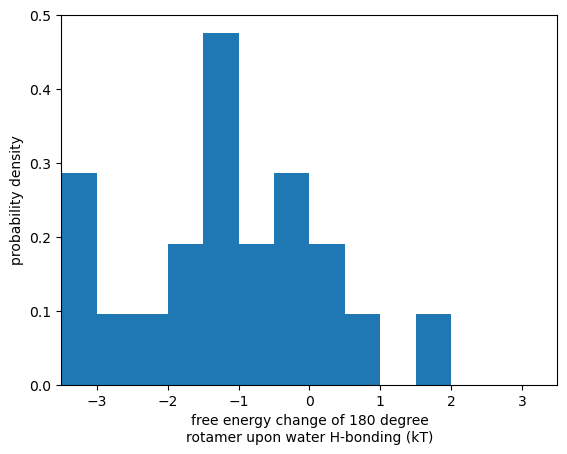

In [12]:
resn = "thr"
ddG_all, weights_all = load_process(heatmap_1, resn)
compile_results(ddG_all, weights_all, resn)

In [6]:
####################################################################################
#                                 TRIMMINGS BELOW
####################################################################################